In [ ]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import random
import math


## Run a Simulation One Step 

### Setup Simulation

In [71]:
def setup_graph(network_type, N, p = None, m = None):
    '''
    A function to setup the initial graphs for running games on networks. 
    '''
    # A list of Graph typologies to choose from. Here, we will only use three: random, scale-free, and a lattice.
    network_types = ["random", "scale-free", "lattice"]

    # If an invalid network type is entered raise a ValueError and give a list of valid values.
    if network_type not in network_types:
        raise ValueError(f"Unknown network type {network_type}. Choose one of: random, scale-free, lattice.")

    # Creating an Erdos-Renyi Graph
    if network_type == "random":

        # If the probability value is empty, raise a value error with a message. 
        if p is None:
            raise ValueError("For an Erdos-Renyi graph you must enter a valid value for p.")
        
        # If the probability value is lesser than zero or greater than 1.
        elif not (0 <= p < 1):
            raise ValueError(f"Your probability value ({p}) is invalid; choose a value in [0, 1).")

        # Otherwise, generate an Erdos-Renyi graph
        else:
            G = nx.erdos_renyi_graph(n = N, p = p)

    # Creating a Scale-Free Network
    elif network_type == "scale-free":
        # If m is None raise a value error.
        if m is None:
            raise ValueError(f"For an Barabasi-Albert graph you must enter a valid value for m.")
        
        # If m is lesser than one raise a value error.
        elif not (1 <= m < N):
            raise ValueError(f"For a Barabasi-Albert graph, m must be an integer from 1 to {N - 1}; got {m}.")
        
        # Otherwise, generate a Scale-Free Network
        else:
            G = nx.barabasi_albert_graph(n = N, m = m)

    # Creating a 2D Lattice
    elif network_type == "lattice":
        # 2D lattice needs to be a perfect square
        side = math.isqrt(N)

        # If N isn't a perfect square, raise a ValueError
        if side * side != N:
            raise ValueError(f"For a lattice, N must be a perfect square (e.g., 100, 400); got {N}.")
        
        # Otherwise create a 2D Lattice Graph
        else:
            G = nx.grid_2d_graph(side, side)

            G = nx.convert_node_labels_to_integers(G) # Convert Node labels to integers and not position
    return G

In [149]:
G = setup_graph(network_type="random", N=100, p=0.06)

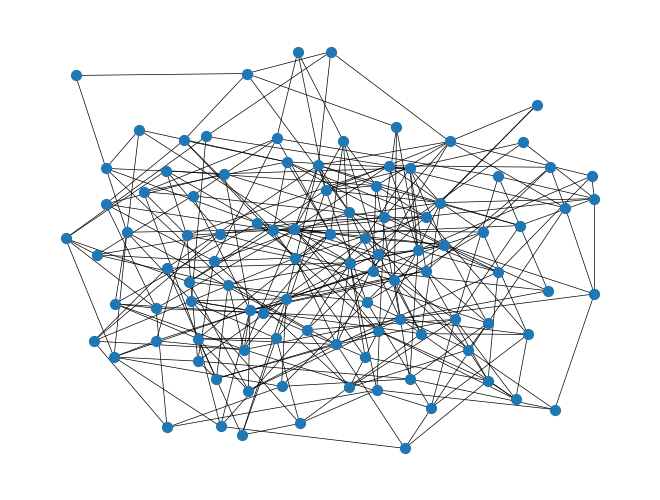

In [150]:
nx.draw(G,
        node_size=50,
        width=0.5)

### Running One Step of a Simulation

In [151]:
def setup_params(G, share):
    '''
    
    '''

    # Keeping a number of all nodes in the graph.
    num_nodes = len(G.nodes())

    # In the Prisoner's Dilemma set up there are two groups: Cooperators and Defections
    group_params = {'C': {'color': "tab:blue"}, 'D': {'color': 'tab:red'}}

    # Population shares for each group (Must sum to 1)
    population_shares = {'C': share, 'D': 1 - share}

    # Create dictionary of agents
    agents = {}

    # Get list of all nodes or agents
    all_nodes = list(G.nodes())

    # Calculate how many agents per group using the items in Population shares
    n_agents_per_group = {}

    for group, pop_share in population_shares.items():
        n_agents_per_group[group] = round(num_nodes * pop_share)

    # Shuffle nodes so agents are randomly placed
    random.shuffle(all_nodes)

    # Assign agents to groups
    node_index = 0
    for group, n_agents in n_agents_per_group.items():
        params = group_params[group]

        for i in range(n_agents):
            node = all_nodes[node_index]

            # Create agent with their group and color
            agents[node] = {
                'group': group,
                'color': params['color']
            }

            node_index += 1

    nx.set_node_attributes(G, agents)

    return agents


In [152]:
agents = setup_params(G, 0.55)

G.nodes

NodeView((0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99))

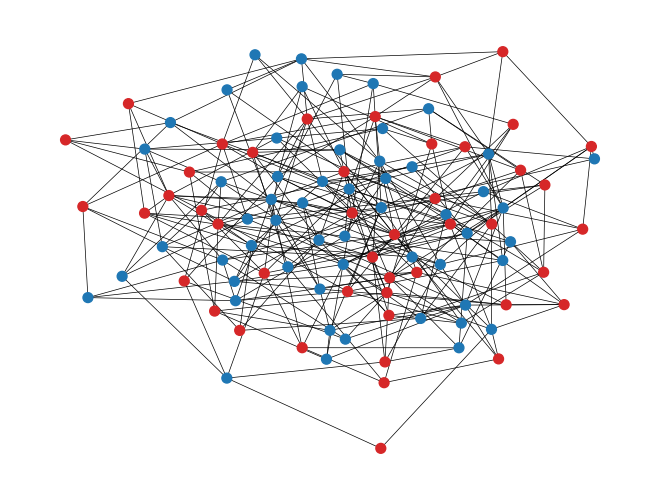

In [153]:
colors = [G.nodes[n]["color"] for n in G.nodes]
nx.draw(G, node_color=colors, node_size=50, width=0.5)

In [156]:
print("\nExample agents:")

for node in list(agents.keys())[:5]: # Loop through first 5 Agents
    agent = agents[node] # Get the values for this agent
    print(f"Agent {node}'s group is {agent['group']} and color is {agent['color']}")



Example agents:
Agent 52's group is C and color is tab:blue
Agent 48's group is C and color is tab:blue
Agent 27's group is C and color is tab:blue
Agent 4's group is C and color is tab:blue
Agent 85's group is C and color is tab:blue


In [31]:
N = len(G.nodes())
N

100